In [1]:
import pandas as pd

df = pd.read_csv("../Level_1/zomato.csv", encoding="latin-1")
print(df.shape)
df.head()

(9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [4]:
# Rating distribution
print(df["Aggregate rating"].describe())

bins = [0, 1, 2, 3, 4, 5]
labels = ["0-1", "1-2", "2-3", "3-4", "4-5"]
df["Rating Range"] = pd.cut(df["Aggregate rating"], bins=bins, labels=labels, include_lowest=True)

rating_dist = df["Rating Range"].value_counts().sort_index()
print("\nRating Range Distribution")
print(rating_dist)

print("\nMost common rating range:", rating_dist.idxmax())
print("Average votes per restaurant:", round(df["Votes"].mean(), 2))

count    9551.000000
mean        2.666370
std         1.516378
min         0.000000
25%         2.500000
50%         3.200000
75%         3.700000
max         4.900000
Name: Aggregate rating, dtype: float64

Rating Range Distribution
Rating Range
0-1    2148
1-2      10
2-3    1891
3-4    4388
4-5    1114
Name: count, dtype: int64

Most common rating range: 3-4
Average votes per restaurant: 156.91


In [2]:
import pandas as pd

df = pd.read_csv(r"C:\Users\ALL AtoZ\Cognifyz_Data_Analytics\Level_1\zomato.csv", encoding="latin-1")
print(df.shape)

(9551, 21)


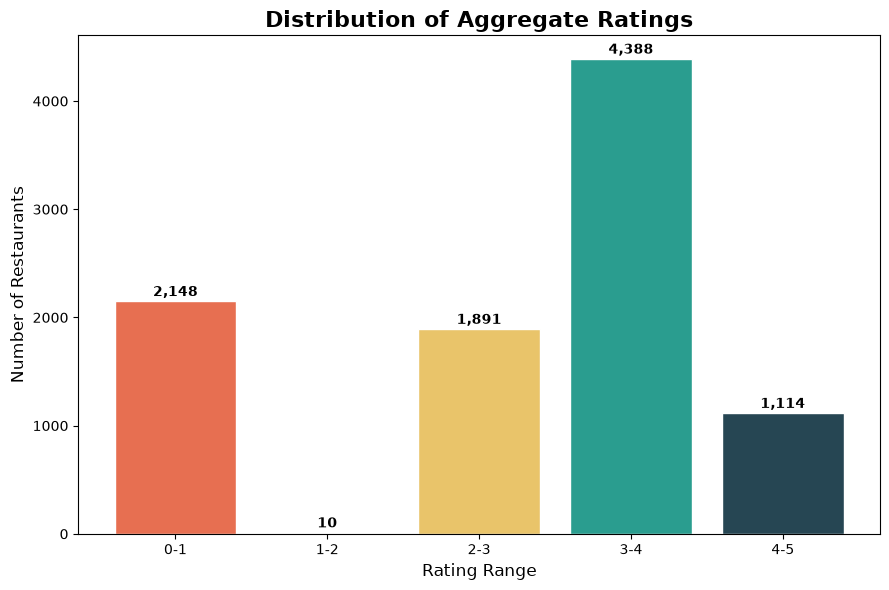

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))
bars = plt.bar(rating_dist.index.astype(str), rating_dist.values,
               color=["#E76F51", "#F4A261", "#E9C46A", "#2A9D8F", "#264653"],
               edgecolor="white")

for bar, count in zip(bars, rating_dist.values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 50,
             f"{count:,}", ha="center", fontweight="bold")

plt.title("Distribution of Aggregate Ratings", fontsize=16, fontweight="bold")
plt.xlabel("Rating Range", fontsize=12)
plt.ylabel("Number of Restaurants", fontsize=12)
plt.tight_layout()
plt.savefig("Rating_Distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### Insights: Restaurant Ratings
- The most common rating range is 3-4, with 4,388 restaurants (45.9%).
- 2,148 restaurants fall in the 0-1 range, mostly unrated restaurants with a rating of 0.
- Only 1,114 restaurants (11.7%) have a rating of 4 or above.
- Restaurants receive 156.91 votes on average.

In [8]:
# Most common cuisine combinations
combo_df = df.dropna(subset=["Cuisines"]).copy()
combo_df["Cuisine Combination"] = combo_df["Cuisines"].apply(
    lambda x: ", ".join(sorted([c.strip() for c in x.split(",")]))
)

top_combos = combo_df["Cuisine Combination"].value_counts().head(10)
print("TOP 10 CUISINE COMBINATIONS")
print(top_combos)

# Average rating for the top combinations
combo_rating = (
    combo_df[combo_df["Cuisine Combination"].isin(top_combos.index)]
    .groupby("Cuisine Combination")["Aggregate rating"]
    .agg(["count", "mean"])
    .round(2)
    .sort_values("mean", ascending=False)
)
print("\nAVERAGE RATING OF TOP COMBINATIONS")
print(combo_rating)

TOP 10 CUISINE COMBINATIONS
Cuisine Combination
North Indian                      936
Chinese, North Indian             616
Mughlai, North Indian             394
Chinese                           354
Fast Food                         354
Chinese, Mughlai, North Indian    306
Cafe                              299
Bakery                            218
Bakery, Desserts                  181
Chinese, Fast Food                159
Name: count, dtype: int64

AVERAGE RATING OF TOP COMBINATIONS
                                count  mean
Cuisine Combination                        
Cafe                              299  2.89
Mughlai, North Indian             394  2.77
Chinese, Mughlai, North Indian    306  2.62
Bakery, Desserts                  181  2.38
Chinese, North Indian             616  2.33
Fast Food                         354  2.12
Chinese, Fast Food                159  2.07
Chinese                           354  2.04
Bakery                            218  1.92
North Indian              

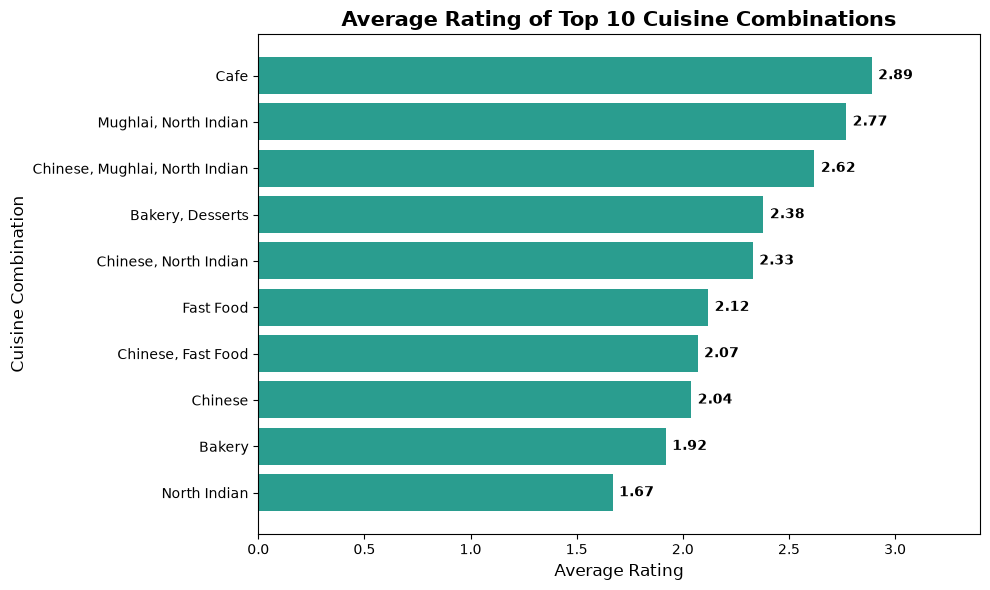

In [9]:
import matplotlib.pyplot as plt

plot_df = combo_rating.sort_values("mean")

plt.figure(figsize=(10, 6))
bars = plt.barh(plot_df.index, plot_df["mean"], color="#2A9D8F")

for bar, val in zip(bars, plot_df["mean"]):
    plt.text(val + 0.03, bar.get_y() + bar.get_height() / 2,
             f"{val:.2f}", va="center", fontweight="bold")

plt.title("Average Rating of Top 10 Cuisine Combinations", fontsize=15, fontweight="bold")
plt.xlabel("Average Rating", fontsize=12)
plt.ylabel("Cuisine Combination", fontsize=12)
plt.xlim(0, 3.4)
plt.tight_layout()
plt.savefig("Cuisine_Combination_Ratings.png", dpi=300, bbox_inches="tight")
plt.show()

### Insights: Cuisine Combinations
- North Indian alone is the most common combination with 936 restaurants, followed by Chinese + North Indian (616) and Mughlai + North Indian (394).
- Among the top 10 combinations, Cafe has the highest average rating (2.89), followed by Mughlai + North Indian (2.77).
- North Indian alone has the lowest average rating (1.67), while adding Mughlai raises it to 2.77.
- Cuisine combinations do show rating differences, but these are averages and not proof of cause.

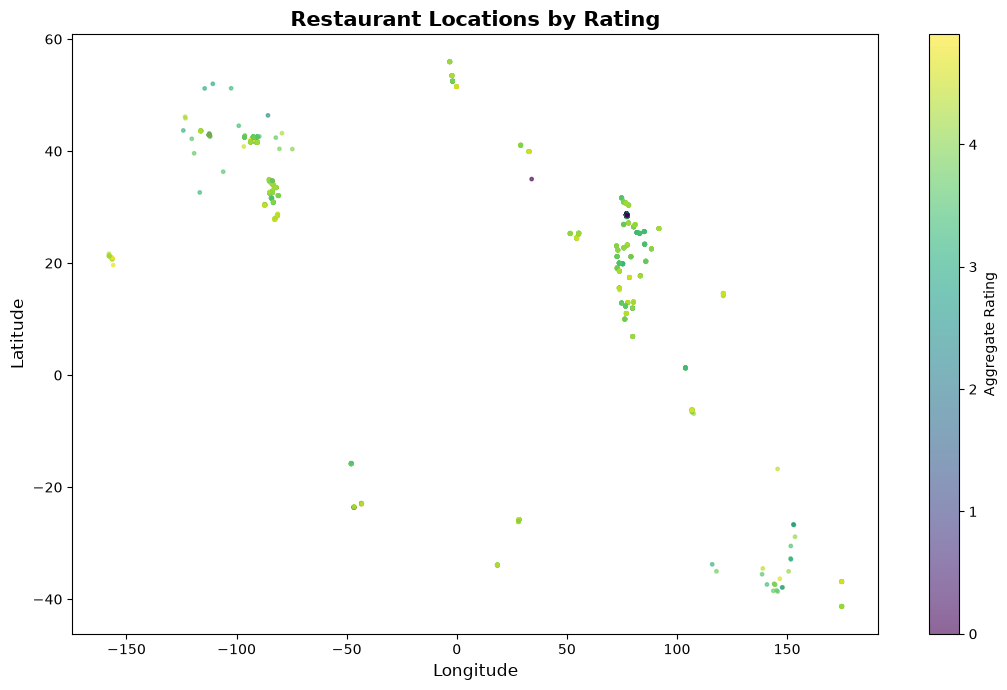

Restaurants plotted: 9052
Country Code
1      8156
216     434
215      80
30       60
214      60
Name: count, dtype: int64


In [10]:
import matplotlib.pyplot as plt

geo_df = df[(df["Longitude"] != 0) & (df["Latitude"] != 0)]

plt.figure(figsize=(11, 7))
scatter = plt.scatter(
    geo_df["Longitude"], geo_df["Latitude"],
    c=geo_df["Aggregate rating"], cmap="viridis",
    s=6, alpha=0.6
)
plt.colorbar(scatter, label="Aggregate Rating")
plt.title("Restaurant Locations by Rating", fontsize=15, fontweight="bold")
plt.xlabel("Longitude", fontsize=12)
plt.ylabel("Latitude", fontsize=12)
plt.tight_layout()
plt.savefig("Restaurant_Locations_Map.png", dpi=300, bbox_inches="tight")
plt.show()

print("Restaurants plotted:", len(geo_df))
print(geo_df["Country Code"].value_counts().head(5))

In [3]:
import pandas as pd

df = pd.read_csv(r"C:\Users\ALL AtoZ\Cognifyz_Data_Analytics\Level_1\zomato.csv", encoding="latin-1")
print(df.shape)

(9551, 21)


In [9]:
import matplotlib.pyplot as plt
geo_df = df[(df["Longitude"] != 0) & (df["Latitude"] != 0)]
ncr = geo_df[geo_df["Longitude"].between(76.8, 77.7) & geo_df["Latitude"].between(28.2, 28.95)]

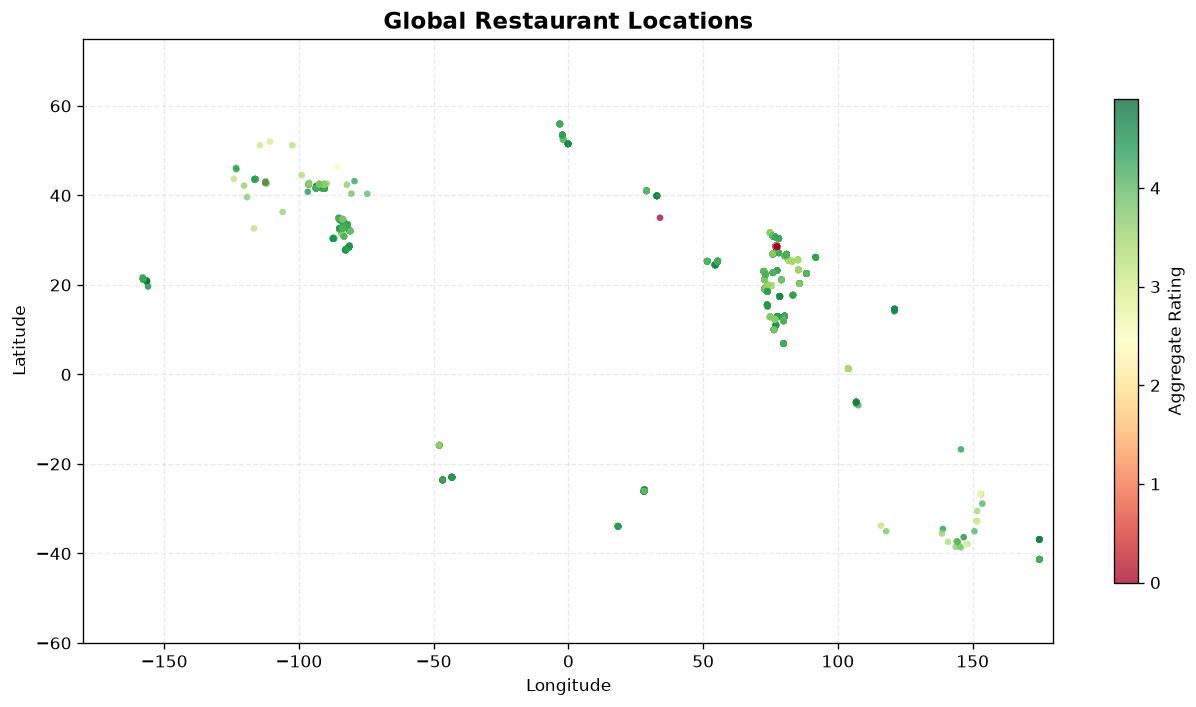

In [10]:
fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
sc = ax.scatter(geo_df["Longitude"], geo_df["Latitude"], c=geo_df["Aggregate rating"],
                cmap="RdYlGn", s=16, alpha=0.75, edgecolors="none")
ax.set_xlim(-180, 180)
ax.set_ylim(-60, 75)
ax.set_title("Global Restaurant Locations", fontsize=14, fontweight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(alpha=0.25, linestyle="--")
fig.colorbar(sc, ax=ax, label="Aggregate Rating", shrink=0.8)
plt.tight_layout()
plt.savefig("Global_Restaurant_Map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

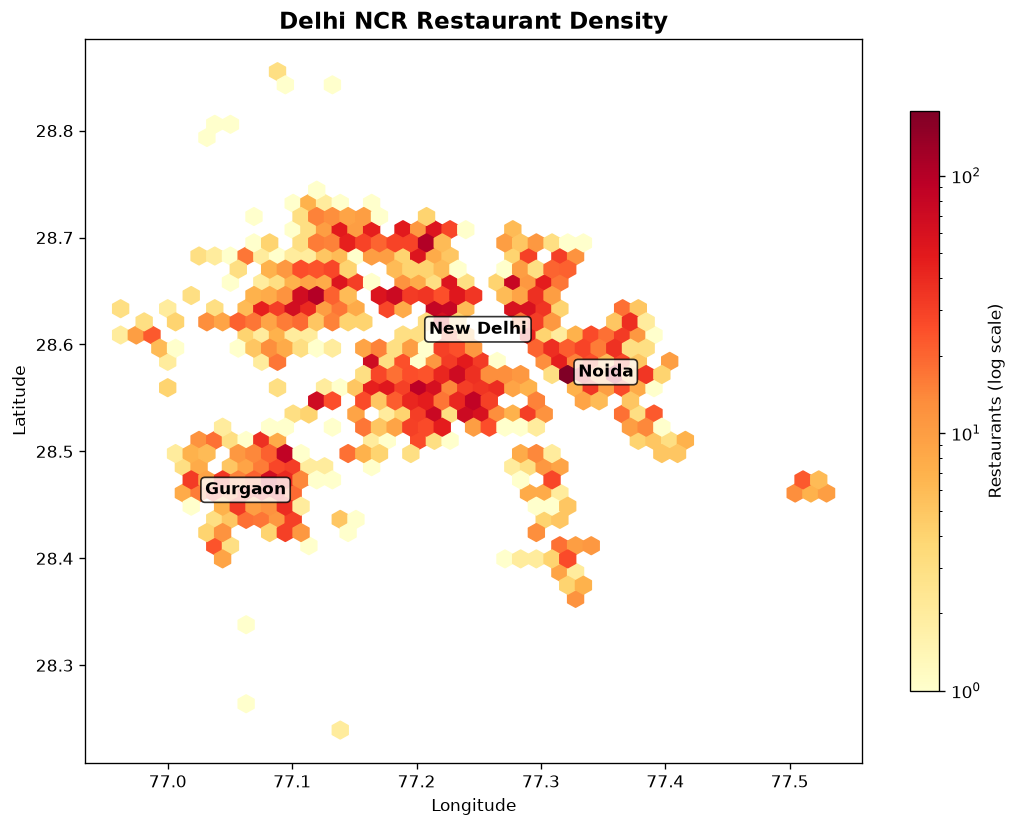

Restaurants plotted: 9052
In Delhi NCR: 7549


In [11]:
fig, ax = plt.subplots(figsize=(9, 7), dpi=120)
hb = ax.hexbin(ncr["Longitude"], ncr["Latitude"], gridsize=45, cmap="YlOrRd", mincnt=1, bins="log")
fig.colorbar(hb, ax=ax, label="Restaurants (log scale)", shrink=0.8)

cities = {"New Delhi": (77.21, 28.61), "Gurgaon": (77.03, 28.46), "Noida": (77.33, 28.57)}
for name, (x, y) in cities.items():
    ax.annotate(name, (x, y), fontsize=10, fontweight="bold", bbox=dict(boxstyle="round,pad=0.25", fc="white", alpha=0.8))

ax.set_title("Delhi NCR Restaurant Density", fontsize=14, fontweight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.savefig("Delhi_NCR_Density_Map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print("Restaurants plotted:", len(geo_df))
print("In Delhi NCR:", len(ncr))

### Insights: Geographic Analysis
- 9,052 restaurants have valid coordinates; 7,549 of them (83.4%) are concentrated in the Delhi NCR region.
- Within NCR, the densest clusters are in New Delhi, Gurgaon and Noida.
- The remaining restaurants form small, isolated clusters across other countries, which shows the dataset is heavily India-centric.
- Restaurant density is highest in the urban core of each city and drops sharply towards the outskirts.

In [13]:
chain_counts = df['Restaurant Name'].value_counts()
chains = chain_counts[chain_counts > 1]

print("Total unique restaurant names:", df['Restaurant Name'].nunique())
print("Names appearing more than once (chains):", len(chains))
chains.head(10)

Total unique restaurant names: 7446
Names appearing more than once (chains): 734


Restaurant Name
Cafe Coffee Day     83
Domino's Pizza      79
Subway              63
Green Chick Chop    51
McDonald's          48
Keventers           34
Pizza Hut           30
Giani               29
Baskin Robbins      28
Barbeque Nation     26
Name: count, dtype: int64

In [14]:
chain_names = chains.head(10).index
top_chains = df[df['Restaurant Name'].isin(chain_names)]

chain_stats = top_chains.groupby('Restaurant Name').agg(
    Outlets=('Restaurant Name', 'count'),
    Avg_Rating=('Aggregate rating', 'mean'),
    Avg_Votes=('Votes', 'mean'),
    Total_Votes=('Votes', 'sum')
).round(2).sort_values('Avg_Rating', ascending=False)

chain_stats

,Outlets,Avg_Rating,Avg_Votes,Total_Votes
Restaurant Name,,,,
Barbeque Nation,26,4.35,1082.38,28142
McDonald's,48,3.34,110.23,5291
Pizza Hut,30,3.32,165.37,4961
Subway,63,2.91,97.21,6124
Keventers,34,2.87,37.15,1263
Domino's Pizza,79,2.74,84.09,6643
Giani,29,2.69,29.45,854
Green Chick Chop,51,2.67,18.90,964
Cafe Coffee Day,83,2.42,29.25,2428


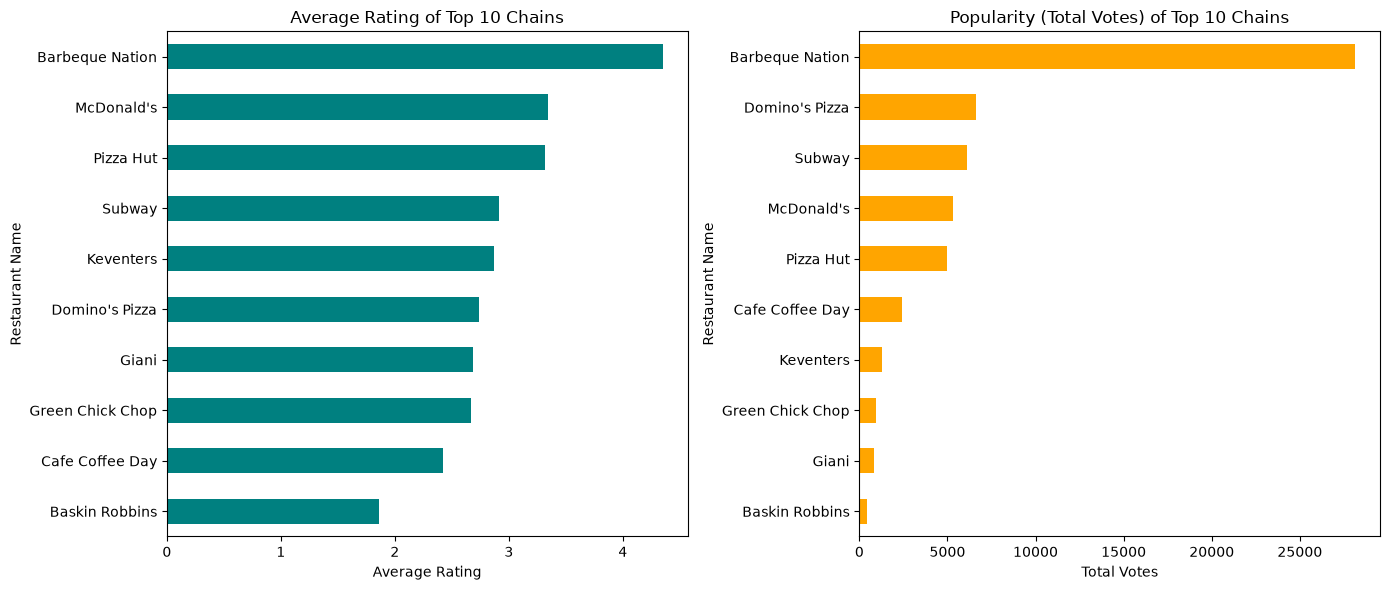

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

chain_stats['Avg_Rating'].sort_values().plot(kind='barh', ax=ax[0], color='teal')
ax[0].set_title('Average Rating of Top 10 Chains')
ax[0].set_xlabel('Average Rating')

chain_stats['Total_Votes'].sort_values().plot(kind='barh', ax=ax[1], color='orange')
ax[1].set_title('Popularity (Total Votes) of Top 10 Chains')
ax[1].set_xlabel('Total Votes')

plt.tight_layout()
plt.savefig('Restaurant_Chains_Analysis.png', dpi=150)
plt.show()

## Insights: Restaurant Chains

- 734 restaurant names appear more than once in the dataset, so chains are present. The biggest are Cafe Coffee Day (83 outlets), Domino's Pizza (79) and Subway (63).
- Barbeque Nation has the highest average rating (4.35) and by far the most votes (28,142 total, about 1,082 per outlet), making it both the best rated and the most popular chain.
- Big outlet count does not mean better ratings: Cafe Coffee Day (83 outlets) averages only 2.42, and Domino's Pizza (79 outlets) averages 2.74.
- Baskin Robbins has the lowest average rating (1.86) and the fewest total votes (428).
- McDonald's (3.34) and Pizza Hut (3.32) sit in the middle, with moderate ratings and vote counts.

In [17]:
chains = df["Restaurant Name"].value_counts()
chains = chains[chains >= 5]

chain_stats = (
    df[df["Restaurant Name"].isin(chains.index)]
    .groupby("Restaurant Name")
    .agg(Outlets=("Restaurant ID", "count"),
         Avg_Rating=("Aggregate rating", "mean"),
         Avg_Votes=("Votes", "mean"))
    .round(2)
    .sort_values("Outlets", ascending=False)
)

print("Chains with 5+ outlets:", len(chain_stats))
print(chain_stats.head(10))

Chains with 5+ outlets: 112
                  Outlets  Avg_Rating  Avg_Votes
Restaurant Name                                 
Cafe Coffee Day        83        2.42      29.25
Domino's Pizza         79        2.74      84.09
Subway                 63        2.91      97.21
Green Chick Chop       51        2.67      18.90
McDonald's             48        3.34     110.23
Keventers              34        2.87      37.15
Pizza Hut              30        3.32     165.37
Giani                  29        2.69      29.45
Baskin Robbins         28        1.86      15.29
Barbeque Nation        26        4.35    1082.38


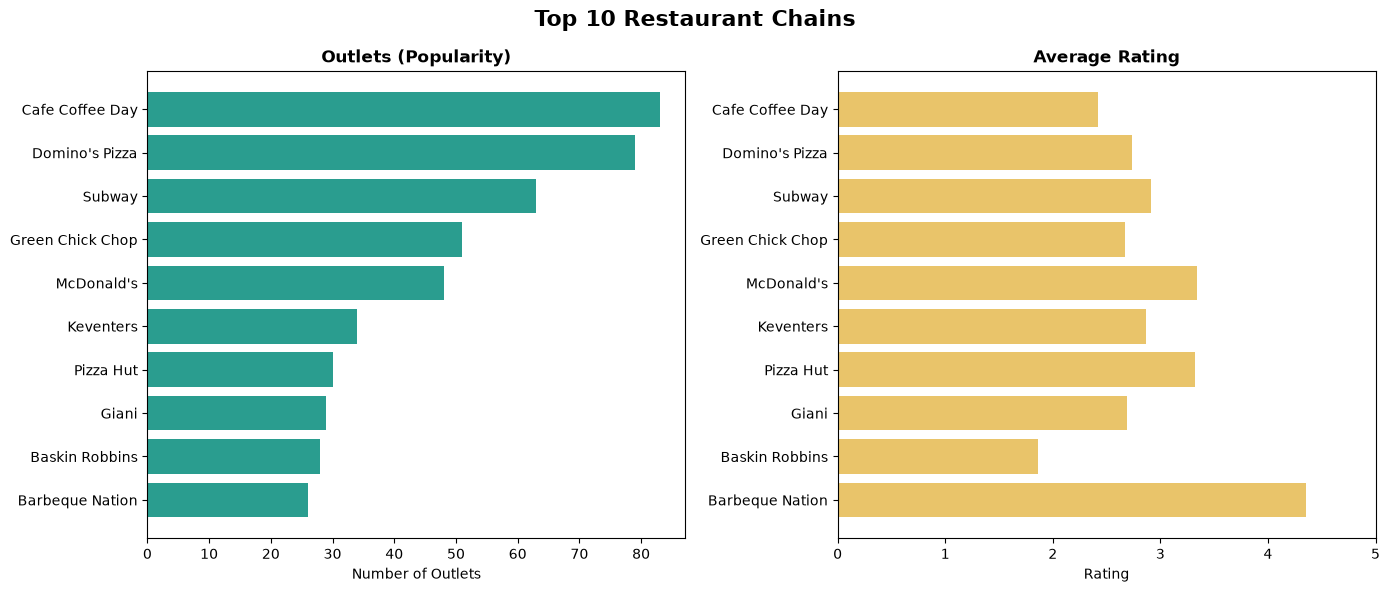

In [18]:
import matplotlib.pyplot as plt

top = chain_stats.head(10).sort_values("Outlets")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(top.index, top["Outlets"], color="#2A9D8F")
axes[0].set_title("Outlets (Popularity)", fontweight="bold")
axes[0].set_xlabel("Number of Outlets")

axes[1].barh(top.index, top["Avg_Rating"], color="#E9C46A")
axes[1].set_title("Average Rating", fontweight="bold")
axes[1].set_xlabel("Rating")
axes[1].set_xlim(0, 5)

fig.suptitle("Top 10 Restaurant Chains", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("Restaurant_Chains_Analysis.png", dpi=300, bbox_inches="tight")
plt.show()

### Insights: Restaurant Chains
- 112 restaurant names appear in 5 or more outlets, so chains form a significant part of the dataset.
- Cafe Coffee Day (83 outlets), Domino's Pizza (79) and Subway (63) are the largest chains.
- Barbeque Nation has the highest average rating (4.35) and by far the most votes (1,082 on average), despite having only 26 outlets.
- McDonald's (3.34) and Pizza Hut (3.32) also rate above the average, while Baskin Robbins has the lowest rating (1.86) among the top 10.
- Having more outlets does not mean